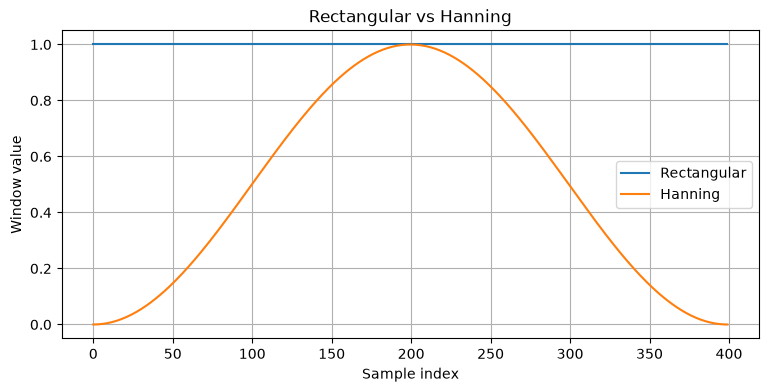

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

#实验1：观察两种窗函数
sr = 16000
win_length = 400

rect_win = np.ones(win_length)

hann_win = np.hanning(win_length)

n = np.arange(win_length)

plt.figure(figsize=(9,4))
plt.plot(n,rect_win,label="Rectangular")
plt.plot(n,hann_win,label="Hanning")

plt.xlabel("Sample index")
plt.ylabel("Window value")
plt.title("Rectangular vs Hanning")
plt.legend()
plt.grid(True)
plt.show()

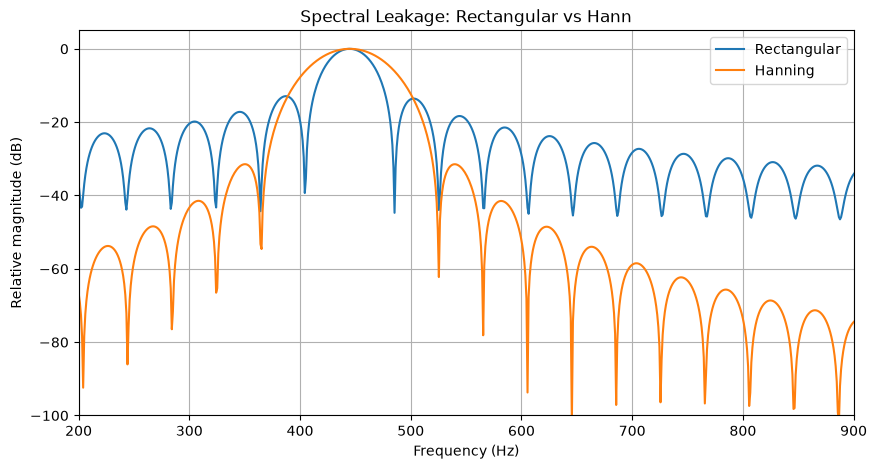

In [2]:
#实验2：使用纯音比较频谱泄露
f = 445
sr = 16000
win_length = 400
n_fft = 16384

t = np.arange(win_length) / sr

x = np.sin(2*np.pi*f*t)

#两种加窗方式
x_rect = x * np.ones(win_length)
x_hann = x * np.hanning(win_length)

#补零后计算rFFT
X_rect = np.fft.rfft(x_rect,n=n_fft)
X_hann = np.fft.rfft(x_hann,n=n_fft)

freqs = np.fft.rfftfreq(n_fft, 1/sr)

mag_rect = np.abs(X_rect)
mag_hann = np.abs(X_hann)

#归一化
mag_rect_norm = mag_rect / (mag_rect.max() + 1e-12)
mag_hann_norm = mag_hann / (mag_hann.max() + 1e-12)

#转为dB
db_rect = 20 * np.log10(mag_rect_norm + 1e-12)
db_hann = 20 * np.log10(mag_hann_norm + 1e-12)

plt.figure(figsize=(10,5))

plt.plot(freqs,db_rect,label="Rectangular")
plt.plot(freqs,db_hann,label="Hanning")

plt.xlim(200,900)
plt.ylim(-100,5)

plt.xlabel("Frequency (Hz)")
plt.ylabel("Relative magnitude (dB)")
plt.title("Spectral Leakage: Rectangular vs Hann")
plt.legend()
plt.grid(True)
plt.show()

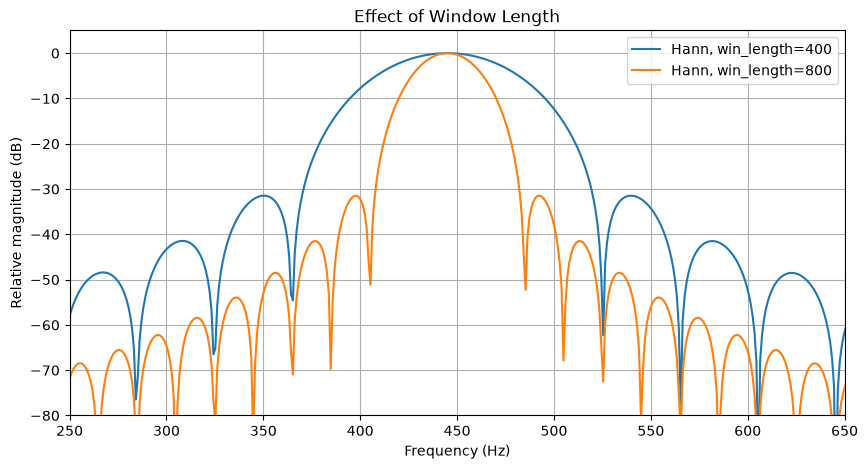

In [3]:
#实验3：改变窗长，观察主瓣宽度
sr = 16000
f = 445
n_fft = 16384

plt.figure(figsize=(10,5))

for win_length in [400,800]:
    t = np.arange(win_length) / sr

    x = np.sin(2*np.pi*f*t)
    win = np.hanning(win_length)

    X = np.fft.rfft(x * win, n=n_fft)

    freqs = np.fft.rfftfreq(n_fft, d=1/sr)

    mag = np.abs(X)
    mag = mag / (mag.max() + 1e-12)

    db = 20 * np.log10(mag + 1e-12)

    plt.plot(
        freqs,
        db,
        label=f"Hann, win_length={win_length}"
    )

plt.xlim(250,650)
plt.ylim(-80,5)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Relative magnitude (dB)")
plt.title("Effect of Window Length")
plt.legend()
plt.grid(True)
plt.show()